# Compute Distances to Resected area

# Batch Wise Run
Run the code for all subjects of a given dataset.

## 📦 Imports

In [ ]:
import mindmap as mm
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy as sp

## 🧠 Data

In [3]:
config   = mm.io.read_config("../../configurations/spike.yml")
subjects = config["SUBS"][:28]              # no epilepsy symptomes until subject 28 included
methods  = ["cset1", "sloreta"]
samp     = ""

## ♾️ Loop

In [4]:
distance = {m:[] for m in methods}
distance["subject"] = []


for sub in subjects:
    
    try:
        data = mm.io.read_dataset(sub, "src", "eeg", "resec", *methods)

        # select time point (50% rising phase)
        sfreq  = data["eeg"].info["sfreq"]
        _, ht  = mm.utils.eeg_rising_phase(data["eeg"], ratio = 0.5)
        t_half = ht/sfreq

        # select source estimate
        for m in methods:
            estimate = mm.utils.select_source_estimate(data[m], data["src"], tp=t_half)
            distance[m].append(mm.utils.measure_distance(estimate, data["resec"]))

        distance["subject"].append(sub)

    except Exception as e:
        print(f"\033[91mFailed to compute error distance for subject '{sub}' due to {e} \033[0m")
        continue

distance = pd.DataFrame(distance)

Failed to compute error distance for subject 'sub-pat01' due to File does not exist: "/media/nino/DATA/SPIKE/derivatives/mindmap/sub-pat01/eeg/sub-pat01_clean_ave.fif" 
DATA SUMMARY
Dataset: spike
Subject: sub-pat02
Retrieved objects:
- eeg
- sloreta
- cset1
- resec
- src
Missing objects:
DATA SUMMARY
Dataset: spike
Subject: sub-pat03
Retrieved objects:
- eeg
- sloreta
- cset1
- resec
- src
Missing objects:
DATA SUMMARY
Dataset: spike
Subject: sub-pat04
Retrieved objects:
- eeg
- sloreta
- cset1
- resec
- src
Missing objects:
DATA SUMMARY
Dataset: spike
Subject: sub-pat05
Retrieved objects:
- eeg
- sloreta
- cset1
- resec
- src
Missing objects:
DATA SUMMARY
Dataset: spike
Subject: sub-pat06
Retrieved objects:
- eeg
- sloreta
- cset1
- resec
- src
Missing objects:
DATA SUMMARY
Dataset: spike
Subject: sub-pat07
Retrieved objects:
- eeg
- sloreta
- cset1
- resec
- src
Missing objects:
DATA SUMMARY
Dataset: spike
Subject: sub-pat08
Retrieved objects:
- eeg
- sloreta
- cset1
- resec
- src
M

Average difference:  0.0018414233149159354


WilcoxonResult(statistic=174.0, pvalue=0.9696103704263741)

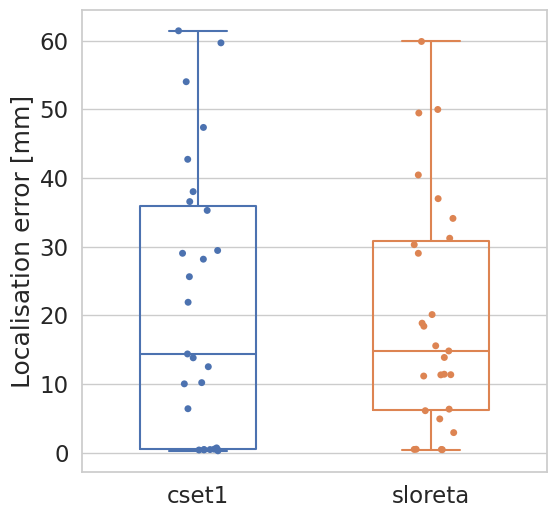

In [12]:
sns.set_theme(font_scale=1.5)
plt.figure(figsize=(6, 6))
sns.set_style("whitegrid")
ax  = sns.boxplot(data=distance*1000, order=["cset1", "sloreta"], fill=False, showfliers=False, width=0.5)
ax2 = sns.stripplot(data=distance*1000, order=["cset1", "sloreta"])

ax.set(ylabel="Localisation error [mm]")

print("Average difference: ", abs(distance["cset1"].mean() - distance["sloreta"].mean()))
sp.stats.wilcoxon(distance["cset1"].values, distance["sloreta"].values)

# Subject Wise Run

Run the code step by step for a single subject.

## Imports

In [1]:
import mindmap as mm 
import mne
import pandas as pd
import numpy as np
import pyvista as pv
import seaborn as sns
import matplotlib.pyplot as plt

## Data

In [2]:
# configuration
config = mm.io.read_config("../../configurations/spike.yml")
sub = config["SUBS"][3]

# data
data = mm.io.read_dataset(sub, "src", "sloreta", "cset", "cset_error2", "cset_error1", "resec", "eeg_inv")

sfreq = data["eeg_inv"].info["sfreq"]

_, ht = mm.utils.eeg_rising_phase(data["eeg_inv"], ratio=0.5)
_, pt = mm.utils.eeg_rising_phase(data["eeg_inv"], ratio=1)

t_half = ht/sfreq 
t_peak = pt/sfreq

print(f"50% rising phase time: {t_half:03}")
print(f"Peak time: {t_peak:03}")

OSError: SourceEstimate File(s) not found for: PosixPath('/media/nino/DATA/SPIKE/derivatives/mindmap/sub-pat04/inv/sub-pat04_spike_cset-0.1')

## Visualize Reconstruction

In [45]:
recon = data["cset"]

mm.viz.plot_brain_time_series(data["src"], np.abs(recon.data), cmap="Reds", sfreq=sfreq, t_start=t_peak-0.05)

Widget(value='<iframe src="http://localhost:38847/index.html?ui=P_0x7ed6ea3d3560_28&reconnect=auto" class="pyv…

## Utilities

## Compute distance

In [40]:
# select source reconstruction
recon = data["cset"]

In [51]:
# source estimate
tp, ba, se = select_source_estimate(recon, data["src"], tp=t_half)

# cloud point of resected area
hole = np.argwhere(data["resec"].get_fdata()>0)
hole = mne.transforms.apply_trans(data["resec"].affine, hole)/1000      # cras?

# distance
dist = measure_distance(se, hole, x=1)
print(f"Distance Error: {dist*1000:.1f} mm, or {dist:.4f} m")
print(f"Selected time point: {tp:.3f} s")

# plot
plotter = mm.viz.plot_brain_signal(data["src"], np.abs(ba), cmap="Reds")
#plotter.add_mesh(pv.PolyData(hole), style="points_gaussian", point_size=5,  emissive=True, color="purple", label="Resected Area")
plotter.add_mesh(pv.PolyData(se), render_points_as_spheres=True, point_size=20, color="green", label="Source Estimation")
plotter.add_legend(face="circle")
plotter.show()

Distance Error: 2.0 mm, or 0.0020 m
Selected time point: 0.474 s


Widget(value='<iframe src="http://localhost:45207/index.html?ui=P_0x725a6c98d8e0_18&reconnect=auto" class="pyv…

## Create Distance Plot

In [18]:
subjects = [f"sub-pat{i+1:02d}" for i in range(28)]


distances = np.inf*np.ones((len(subjects),4))
for i,sub in enumerate(subjects):
    try:
        data = mm.io.read_dataset(sub, "src", "sloreta", "cset", "cset_error2", "cset_error1", "eeg_inv", "resec")

        sfreq  = data["eeg_inv"].info["sfreq"]
        _, ht  = mm.utils.eeg_rising_phase(data["eeg_inv"], ratio=0.5)
        t_half = ht/sfreq 

        _, _, sloreta = select_source_estimate(data["sloreta"], data["src"], tp=t_half)
        _, _, cset    = select_source_estimate(data["cset"], data["src"], tp=t_half)
        _, _, cset2   = select_source_estimate(data["cset_error2"], data["src"], tp=t_half)
        _, _, cset3   = select_source_estimate(data["cset_error1"], data["src"], tp=t_half)

        resec = np.argwhere(data["resec"].get_fdata()>0)
        resec = mne.transforms.apply_trans(data["resec"].affine, resec)/1000

        distances[i,0] = measure_distance(sloreta, resec, x=1)*100
        distances[i,1] = measure_distance(cset, resec, x=1)*100
        distances[i,2] = measure_distance(cset2, resec, x=1)*100
        distances[i,3] = measure_distance(cset3, resec, x=1)*100
        
    except Exception as e:
        print(f"Subject {sub} failed because {e}")
        distances[i] = None

distances = pd.DataFrame(distances, columns=["sLORETA", "CSET", "CSET*", "CSET**"])

# OHBM subjects:
id = [7, 8, 9, 13, 16, 25, 10, 19]
distances["CSET***"] = None
distances["CSET***"][id] = distances["CSET**"][id]

Subject sub-pat01 failed because File does not exist: "/media/nino/DATA/SPIKE/derivatives/mindmap/sub-pat01/fwd/sub-pat01_bem-sim-fwd.fif"
No resection found for subject sub-pat02'
Some arguments did not correpond to the list of available objects to load. Check the list of arguments again.
Subject sub-pat02 failed because 'resec'
No resection found for subject sub-pat04'
Some arguments did not correpond to the list of available objects to load. Check the list of arguments again.
Subject sub-pat04 failed because 'resec'
No resection found for subject sub-pat07'
Some arguments did not correpond to the list of available objects to load. Check the list of arguments again.
Subject sub-pat07 failed because 'resec'
No resection found for subject sub-pat18'
Some arguments did not correpond to the list of available objects to load. Check the list of arguments again.
Subject sub-pat18 failed because 'resec'
No resection found for subject sub-pat19'
Some arguments did not correpond to the list of

/tmp/ipykernel_7924/1703942261.py:35: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  distances["CSET***"][id] = distances["CSET**"][id]


[Text(0, 0.5, 'Localisation error [cm]')]

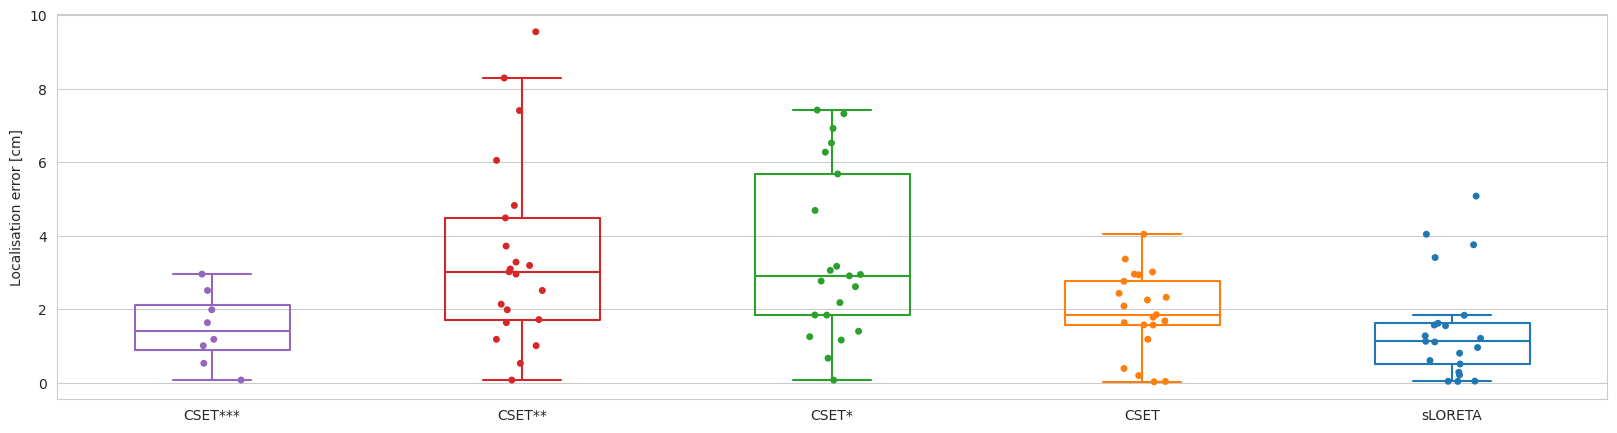

In [33]:
plt.figure(figsize=(20, 5))
sns.set_style("whitegrid")
ax  = sns.boxplot(data=distances, order=["CSET***", "CSET**", "CSET*",  "CSET", "sLORETA"], fill=False, showfliers=False, width=0.5)
ax2 = sns.stripplot(data=distances, order=["CSET***", "CSET**", "CSET*",  "CSET", "sLORETA"])

ax.set(ylabel="Localisation error [cm]")